# 1. The model

**The question.** Large firms grow less erratically than small ones, but much more erratically than a
sum of independent parts would. If $v$ is the volatility of a firm's yearly growth rate and $\bar S$ its
mean size over its life, in Compustat (Moran, Secchi & Bouchaud 2024, "MSB")

$$\mathbb E[v^q\mid\bar S]\sim\bar S^{-\zeta_q},\qquad \zeta_q = 0.20,\ 0.39,\ 0.51,\ 0.58\quad(q=1,\dots,4)$$

over four decades of size. The ratios $\zeta_q/\zeta_1 = 2.0, 2.6, 2.9$ lie below $q$ (*multiscaling*): if
$v$ were a function of size times a random factor with a size-independent law, they would be exactly $q$.
MSB add more facts: $v/\mathbb E[v\mid\bar S]$ has a universal law with power-law tail $b\simeq4.6$, rescaled
growth stays fat-tailed at every size, multi-year growth is persistent, co-movement with the aggregate
rises with size, and firm sizes follow Zipf's law. Granular models (a firm as a sum of independent
subunits) give a volatility law of fixed shape and hence $\zeta_q=q\zeta_1$.

We ask whether an economy of **interacting** firms can produce these facts.

**The model.** Firm $i=1,\dots,N$ has size $x_i$, and $m=N^{-1}\sum_j x_j$ is the mean firm. Firms sit on a
configuration-model graph with degree law $p(k)\propto k^{-\alpha}$ and mean degree $C$, and

$$dx_i = x_i\Big[1-\frac{x_i}{m}+\sum_j J_{ij}\frac{x_j}{m}\Big]dt+\sqrt{D\,m\,x_i}\;dW_i,
\qquad J_{ij}=A_{ij}\Big(\frac{\mu}{C}+\frac{\sigma z_{ij}}{\sqrt C}\Big),$$

with independent Gaussians $z_{ij}$ ($z_{ij}$, $z_{ji}$ uncorrelated) and $\mu<0$ net competition. A firm that
reaches $x_i=0$ exits and a newborn of size $Dm$ takes its node and couplings: a new firm in the same niche.

Every term is the standard disordered GLV with the carrying capacity and the interaction unit set to the
**mean firm**, plus birth–death noise with unit $Dm$. Everything is homogeneous of degree one in the sizes,
so the economy has no preferred size: $m$ grows at a rate the dynamics selects, and a firm is large or
small only relative to the others. Five parameters: $\mu$, $\sigma$, $\alpha$, $C$, $D$.

The **deterministic** version (the thesis model) replaces the noise by an immigration floor
$\lambda(m-x_i)$; it is the $D\to0$ limit of the phase diagram (notebook 02) and its one-firm theory is
notebook 03.

**Reference point**: $\alpha=2.5$, $\sigma=1.70$, $D=0.1$, $C=200$, $\mu=-1.76$, $N\ge16000$, one year $=0.5$
time units. **Sign convention**: the code uses the opposite sign, `mu=1.76` is competition.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from economy import configuration_coupling, integrate_demographic, lives, zeta_bins, hill, tidy, MSB_ZETA

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})

## Relative sizes: the economy as one firm in a field

Write $x_i=mS_i$. By Itô's rule, with $\bar f=\dot m/m$ the growth rate of the mean firm,

$$dS_i=S_i\big[F_i-\bar f\big]dt+\sqrt{DS_i}\,dW_i-\frac{S_i}{N}\sum_j\sqrt{DS_j}\,dW_j,\qquad
F_i=1-S_i+\sum_jJ_{ij}S_j,$$

and $\bar f=N^{-1}\sum_iS_iF_i+D\nu(t)$ keeps $\sum_iS_i=N$: the first part balances the drift, and the second,
with $\nu$ the entries per node per unit time, the size $D$ each newborn adds (every entry dilutes all firms;
$D\nu\simeq0.06$ at the reference point). The third term, of order
$N^{-1/2}$, is each firm's share of the aggregate noise. This is a replicator equation with birth–death
noise. Collecting everything but the firm's own self-limitation into a **field**,

$$\boxed{dS_i=S_i\big[\Phi_i(t)-S_i\big]dt+\sqrt{DS_i}\,dW_i+O(N^{-1/2}),\qquad
\Phi_i(t)=1+\sum_jJ_{ij}S_j(t)-\bar f(t).}$$

A logistic equation with a moving carrying capacity: a firm whose field stays at $\Phi$ relaxes to the
plateau $x_i=m\Phi$ at rate $\Phi$; a firm with $\Phi<0$ shrinks to exit. Exit is at $S_i=0$, entry at $S_i=D$.

If $\bar f$ self-averages to a constant $f^*$ at large $N$, the substitution $S=ry$, $t'=rt$ with $r=1-f^*$ gives
the GLV with demographic noise of Altieri et al. (2021) on the same graph, with noise $D/r^2$. On the complete
graph, and with an immigration floor in place of the noise, it is the chaotic-turnover model of Bunin (2017)
and Mallmin, Traulsen & De Monte (PNAS 2024). The normalisation adds the growth rate as an output, a common
mode at finite $N$, and observables measured relative to the mean firm, as in firm data.

`integrate_demographic` (in `economy.py`, the code the notebooks share) integrates exactly this relative form by Euler–Maruyama (step 0.01), with
$\sum_iS_i=N$ restored after every step and a death counter per node, so a **life** is a maximal run of
samples with the same counter. The restoring after an entry is the dilution term $D\nu$ of $\bar f$.

## A small economy

The reference graph ($\alpha=2.5$, $C=200$) is saturated below $N\approx16000$, and one such economy takes
about an hour. To look at the dynamics we use $N=4000$, $C=100$ here; the production numbers are in
notebooks 04–06.

In [2]:
N, C, SIGMA, D, MU = 4000, 100, 1.70, 0.1, 1.76
a = configuration_coupling(N, MU, SIGMA, alpha=2.5, mean_degree=C, seed=0)
deg = np.diff(a.indptr)
r = integrate_demographic(a, D=D, tmax=340.0, t_start=100.0, dt_save=0.5, seed=0)
t, S, L = r["t"], r["S"], r["life"]
nu = np.diff(L, axis=1).sum(0) / (N * np.diff(t))            # entries per node per unit time
fbar = (S * (1 - S - a @ S)).sum(0) / N + D * np.r_[nu, nu[-1]]   # drift plus entry dilution
Phi = 1 - a @ S - fbar
print(f"degrees {deg.min()}..{deg.max()}, mean {deg.mean():.0f}; samples {S.shape[1]}")
print(f"growth rate of the mean firm: {fbar.mean():+.3f} ± {fbar.std():.3f} per unit time")
print(f"turnover: {(L[:, -1] - L[:, 0]).sum() / N / (t[-1] - t[0]):.3f} exits per node per unit time")

degrees 29..2448, mean 82; samples 481
growth rate of the mean firm: -0.214 ± 0.045 per unit time
turnover: 0.512 exits per node per unit time


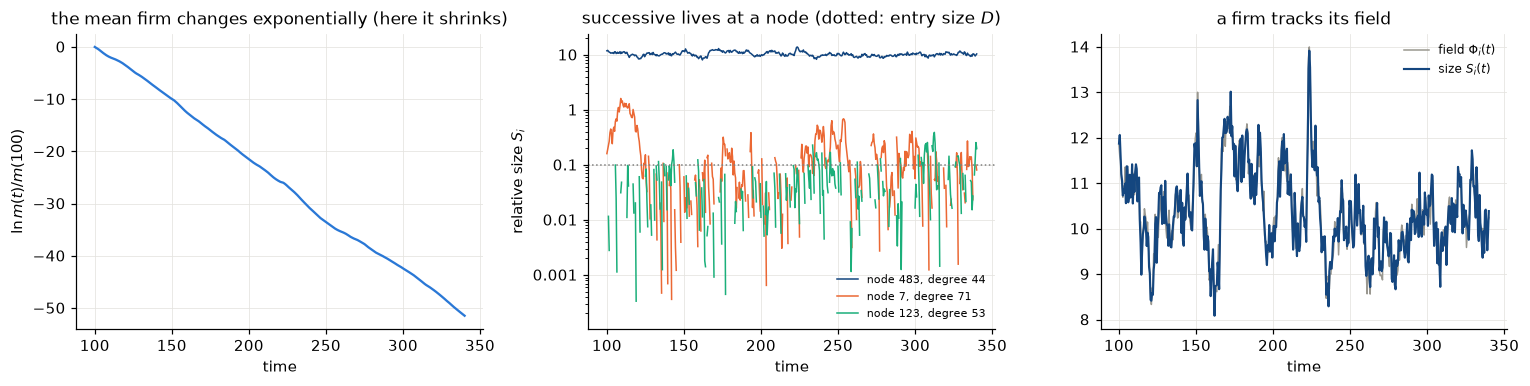

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
lnm = np.concatenate([[0], np.cumsum(fbar[:-1] * np.diff(t))])
ax[0].plot(t, lnm, color="#2a78d6")
ax[0].set(xlabel="time", ylabel=r"$\ln m(t)/m(100)$", title="the mean firm changes exponentially (here it shrinks)")
for i, c in zip((np.argmax(S.mean(1)), 7, 123), ("#14467f", "#eb6834", "#1baf7a")):
    x = S[i].copy()
    x[np.r_[False, np.diff(L[i]) > 0]] = np.nan          # break the line at each exit
    ax[1].semilogy(t, x, color=c, lw=1, label=f"node {i}, degree {deg[i]}")
ax[1].axhline(D, color="grey", ls=":", lw=1)
ax[1].set(xlabel="time", ylabel=r"relative size $S_i$", title="successive lives at a node (dotted: entry size $D$)")
ax[1].legend(frameon=False, fontsize=7)
i = np.argmax(S.mean(1))
ax[2].plot(t, Phi[i], color="#9a9890", lw=1, label=r"field $\Phi_i(t)$")
ax[2].plot(t, S[i], color="#14467f", lw=1.4, label=r"size $S_i(t)$")
ax[2].set(xlabel="time", title="a firm tracks its field")
ax[2].legend(frameon=False, fontsize=8)
for x in ax:
    tidy(x)
plt.tight_layout()

Without noise, averaging $d\ln S_i/dt=\Phi_i-S_i$ over a window in which $\ln S_i$ returns to its start gives
$\bar S_i=\bar\Phi_i$ exactly: **a firm's size is its mean field**. With noise, Itô adds $-D/2S$ to the log
drift, so $\bar S_i=\bar\Phi_i-\tfrac D2\overline{S_i^{-1}}$ for a life that ends where it started. Per life this holds to
about $5\%$: a life selected for its length is not a fair sample of its own noise. Without selection, the log
drift $\Phi_i-S_i-D/2S_i$ is exact step by step, provided $\bar f$ includes the entry dilution $D\nu$ (without it
the residual is $-D\nu$):

In [4]:
lv = [x for x in lives(S, L) if x[2] >= 40]
sb = np.array([x[0] for x in lv])
pb = np.array([Phi[x[5], x[6]:x[6] + x[2] + 1].mean() for x in lv])
inv = np.array([(1 / S[x[5], x[6]:x[6] + x[2] + 1]).mean() for x in lv])
print(f"{len(lv)} lives with >= 40 growth rates: corr(Sbar, Phibar) = {np.corrcoef(sb, pb)[0, 1]:.3f}, "
      f"median Sbar / (Phibar - D/2 <1/S>) = {np.median(sb / (pb - D / 2 * inv)):.3f}")

rf = integrate_demographic(a, D=D, tmax=130.0, t_start=100.0, dt_save=0.01, seed=0)     # every Euler step
Sf, Lf = rf["S"], rf["life"]
nuf = np.diff(Lf, axis=1).sum(0) / (N * 0.01)
alive = (np.diff(Lf, axis=1) == 0) & (Sf[:, :-1] > 0.3)
dl = np.diff(np.log(Sf), axis=1) / 0.01
drift = (Sf * (1 - Sf - a @ Sf)).sum(0) / N
for name, fb in (("with entry dilution", drift + D * np.r_[nuf, nuf[-1]]), ("drift only", drift)):
    res = (dl - (1 - a @ Sf - fb - Sf - D / (2 * Sf))[:, :-1])[alive]
    print(f"step residual of d ln S/dt, S > 0.3, {name}: {res.mean():+.4f} ± {res.std() / np.sqrt(res.size):.4f}")


4836 lives with >= 40 growth rates: corr(Sbar, Phibar) = 0.997, median Sbar / (Phibar - D/2 <1/S>) = 1.050


step residual of d ln S/dt, S > 0.3, with entry dilution: +0.0001 ± 0.0012


step residual of d ln S/dt, S > 0.3, drift only: -0.0524 ± 0.0012


## The MSB protocol

Following MSB we use an **unbalanced panel**: a life runs from a birth to the next exit at the same node,
lives cut by the observation window are kept, and a life's volatility is $v=\sqrt{\pi/2}$ times the mean
absolute deviation of its yearly growth rates $g=\Delta\ln S$ (step 0.5) around their mean. $\bar S$ is the
life's mean relative size, and lives need at least $n_{\min}$ growth rates. Exponents are least-squares
slopes of $\ln\mathbb E[v^q\mid\bar S]$ against $\ln\bar S$ over 25 equal-count bins, all bins included
(`lives`, `zeta_bins`).

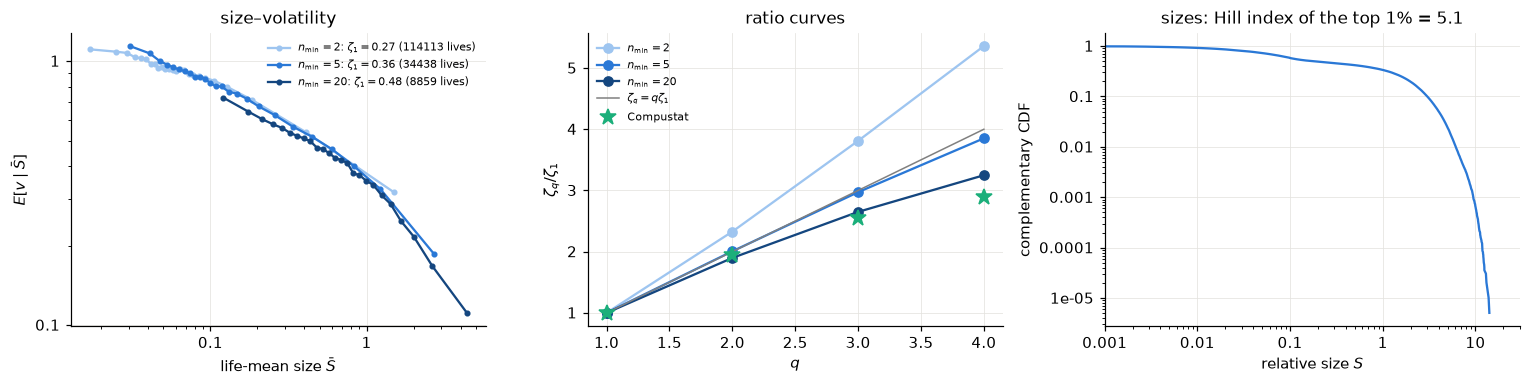

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
q = np.arange(1, 5)
for nm, col in ((2, "#9ec5f0"), (5, "#2a78d6"), (20, "#14467f")):
    lv = [x for x in lives(S, L) if x[2] >= nm]
    Sb, v = np.array([x[0] for x in lv]), np.array([x[1] for x in lv])
    z = zeta_bins(Sb, v)[0]
    P = np.array_split(np.argsort(Sb), 25)
    ax[0].loglog([Sb[p].mean() for p in P], [v[p].mean() for p in P], "o-", color=col, ms=3,
                 label=rf"$n_{{\min}}={nm}$: $\zeta_1={z[0]:.2f}$ ({len(lv)} lives)")
    ax[1].plot(q, z / z[0], "o-", color=col, label=rf"$n_{{\min}}={nm}$")
ax[0].set(xlabel=r"life-mean size $\bar S$", ylabel=r"$E[v\mid\bar S]$", title="size–volatility")
ax[0].legend(frameon=False, fontsize=7)
ax[1].plot(q, q, color="grey", lw=1, label=r"$\zeta_q=q\zeta_1$")
ax[1].plot(q, MSB_ZETA / MSB_ZETA[0], "*", color="#1baf7a", ms=11, label="Compustat")
ax[1].set(xlabel="$q$", ylabel=r"$\zeta_q/\zeta_1$", title="ratio curves")
ax[1].legend(frameon=False, fontsize=7)
x = np.sort(S[:, ::10].ravel())[::-1]
ax[2].loglog(x, np.arange(1, x.size + 1) / x.size, color="#2a78d6")
ax[2].set(xlabel="relative size $S$", ylabel="complementary CDF", xlim=(1e-3, 30),
          title=f"sizes: Hill index of the top 1% = {hill(x, 0.01):.1f}")
for a_ in ax:
    tidy(a_)
plt.tight_layout()

Even this small economy shows the shape: a monotone decline of volatility with size and, for long lives
($n_{\min}=20$), a ratio curve that bends below $q$; very short lives push the ratios above $q$. The level of
$\zeta_1$ is not converged at this $N$ and $C$ (notebook 06: it converges by $N\approx16000$). Sizes are
capped at a few times the mean, so there is no Zipf law. Whether the mean firm grows or shrinks depends on
$(\mu,\sigma)$: this point sits just on the shrinking side of the zero-growth line (notebook 02).

The rest of the story:

| notebook | content |
|---|---|
| 02 | phase diagram: where the economy keeps fluctuating and where it grows |
| 03 | deterministic limit ($\lambda$ floor): exact one-firm theory, life cycles, lifetime law |
| 04 | one firm is enough; the field law; the volatility law $v^2\simeq V_F+B$ |
| 05 | the multiscaling mechanism $\zeta_q=(q/2)\,b\,\langle w\rangle_q$ (main result) |
| 06 | every MSB fact at the reference point, robustness, and why there is no Zipf law |